# Pneumonia Detection from Chest X-ray Images
### Modified replication of Kundu et al. (2021) + CBAM-DenseNet121 enhancement

**Run the numbered code cells from top to bottom.** Each experiment cell generates and saves its own graphs, tables and report evidence—there are no separate plotting-only cells.

**Reference:** Kundu et al. (2021), “Pneumonia detection in chest X-ray images using an ensemble of deep learning models,” PLOS ONE, 16(9), e0256630. DOI: https://doi.org/10.1371/journal.pone.0256630

**Scope note:** This is a modified replication. It uses a stratified validation split from the training folder and the provided official test folder. It does not reproduce the paper's complete five-fold cross-validation or every additional-dataset experiment. This is an academic experiment, not a clinically validated diagnostic tool.

## CELL 1 — Install libraries, import packages, set random seeds, verify GPU, and create all project folders.

In [1]:
!pip -q install --upgrade kaggle scikit-learn seaborn scipy

import os, sys, json, time, random, shutil, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             roc_auc_score, roc_curve)
from scipy.stats import binomtest

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMG_SIZE, BATCH_SIZE, NUM_WORKERS = 224, 32, 2
BASELINE_EPOCHS, CBAM_EPOCHS = 30, 15
CLASS_NAMES = ["NORMAL", "PNEUMONIA"]

ROOT = Path("/content/pneumonia_project")
DATA_DIR, OUT_DIR = ROOT/"data", ROOT/"outputs"
FIG_DIR, MODEL_DIR = OUT_DIR/"figures", ROOT/"models"
for folder in [DATA_DIR, OUT_DIR, FIG_DIR, MODEL_DIR]: folder.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Torchvision:", __import__("torchvision").__version__)
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU not detected. In Colab select Runtime > Change runtime type > T4 GPU.")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
Device: cuda
GPU: Tesla T4


## CELL 2 — Configure Kaggle securely, download the exact research dataset if needed, extract it, and verify its folders.

In [2]:
# The cell reuses an already-extracted dataset. If Kaggle credentials are not configured,
# it asks you to upload kaggle.json. Never print or share the token contents.
from google.colab import files

KAGGLE_CONFIG = Path("/root/.kaggle/kaggle.json")
KAGGLE_CONFIG.parent.mkdir(parents=True, exist_ok=True)

if not KAGGLE_CONFIG.exists():
    print("Upload your kaggle.json file.")
    uploaded = files.upload()
    if "kaggle.json" not in uploaded:
        raise FileNotFoundError("The uploaded file must be named kaggle.json.")
    shutil.copy("kaggle.json", KAGGLE_CONFIG)
    os.remove("kaggle.json")
    os.chmod(KAGGLE_CONFIG, 0o600)
    print("Kaggle API credentials configured (secret values are not displayed).")
else:
    print("Kaggle API credentials already configured.")

DATA_ROOT = DATA_DIR/"chest_xray"
if not ((DATA_ROOT/"train"/"NORMAL").is_dir() and (DATA_ROOT/"test"/"PNEUMONIA").is_dir()):
    print("Downloading paultimothymooney/chest-xray-pneumonia (about 2.46 GB)...")
    !kaggle datasets download -d paultimothymooney/chest-xray-pneumonia -p /content/pneumonia_project/data
    zip_candidates = list(DATA_DIR.glob("*.zip"))
    if not zip_candidates:
        raise FileNotFoundError("Kaggle download did not produce a ZIP file.")
    with zipfile.ZipFile(zip_candidates[0], "r") as zf:
        zf.extractall(DATA_DIR)
else:
    print("Existing extracted dataset detected; skipping download.")

# Locate expected dataset root even if the ZIP has an extra parent folder.
candidates = list(DATA_DIR.rglob("train"))
DATA_ROOT = None
for train_path in candidates:
    parent = train_path.parent
    if (train_path/"NORMAL").is_dir() and (train_path/"PNEUMONIA").is_dir() and (parent/"test").is_dir():
        DATA_ROOT = parent
        break
if DATA_ROOT is None:
    raise FileNotFoundError("Could not find train/NORMAL, train/PNEUMONIA and test folders.")
print("Dataset root:", DATA_ROOT)
for split in ["train", "test", "val"]:
    p = DATA_ROOT/split
    if p.exists():
        print(split, "contains:", [x.name for x in p.iterdir() if x.is_dir()])
print("Dataset ready.")

Upload your kaggle.json file.


Saving kaggle.json to kaggle.json
Kaggle API credentials configured (secret values are not displayed).
Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [00:12<00:00, 196MB/s]

Dataset root: /content/pneumonia_project/data/chest_xray
train contains: ['NORMAL', 'PNEUMONIA']
test contains: ['NORMAL', 'PNEUMONIA']
val contains: ['NORMAL', 'PNEUMONIA']
Dataset ready.


## CELL 3 — Inspect class counts, create a reproducible stratified train/validation split, display sample X-rays and dataset-distribution graphs, and save split metadata.

Class mapping: {'NORMAL': 0, 'PNEUMONIA': 1}
Original training folder: {'NORMAL': 1341, 'PNEUMONIA': 3875}
Training subset: {'NORMAL': 1140, 'PNEUMONIA': 3293}
Validation subset: {'NORMAL': 201, 'PNEUMONIA': 582}
Official test folder: {'NORMAL': 234, 'PNEUMONIA': 390}


,Partition,NORMAL,PNEUMONIA
0,Train,1140,3293
1,Validation,201,582
2,Official test,234,390


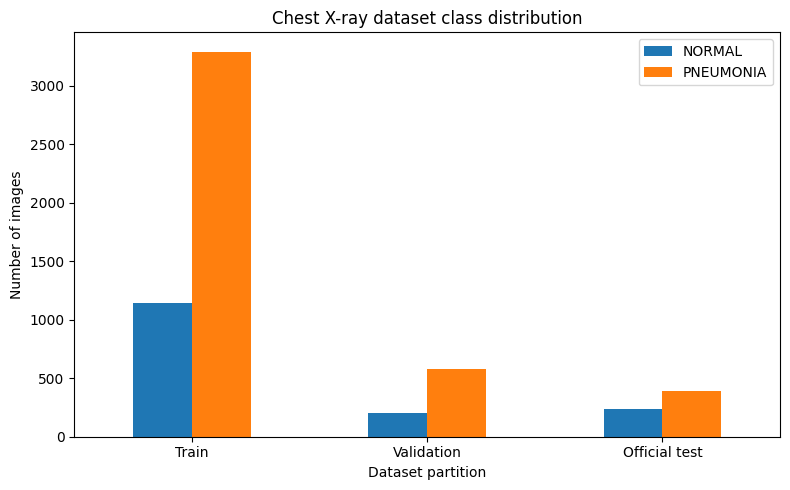

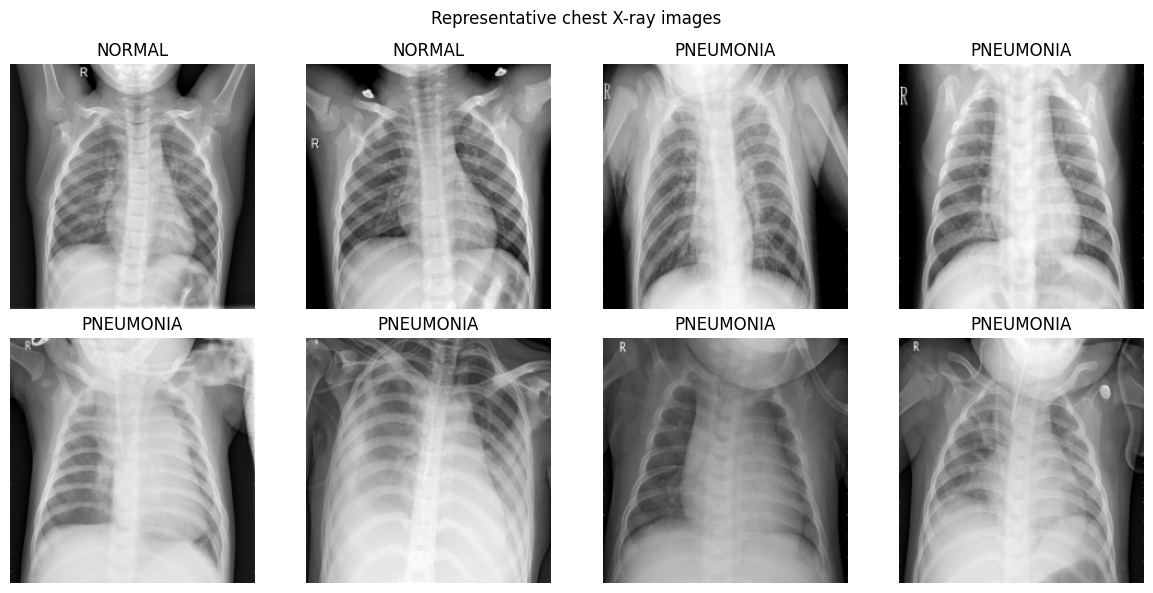

Dataset inspection complete. Split indices and both figures saved.


In [3]:
train_dir, test_dir = DATA_ROOT/"train", DATA_ROOT/"test"
base_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

full_train = datasets.ImageFolder(train_dir, transform=base_transform)
aug_train = datasets.ImageFolder(train_dir, transform=train_transform)
test_dataset = datasets.ImageFolder(test_dir, transform=base_transform)
assert full_train.class_to_idx == {"NORMAL":0, "PNEUMONIA":1}, full_train.class_to_idx
assert test_dataset.class_to_idx == full_train.class_to_idx

targets = np.asarray(full_train.targets)
indices = np.arange(len(targets))
train_idx, val_idx = train_test_split(indices, test_size=0.15, random_state=SEED, stratify=targets)
train_ds, val_ds = Subset(aug_train, train_idx), Subset(full_train, val_idx)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
                          pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
                        pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
                         pin_memory=torch.cuda.is_available())

def counts_for(y):
    return {"NORMAL":int(np.sum(np.asarray(y)==0)), "PNEUMONIA":int(np.sum(np.asarray(y)==1))}
split_counts = pd.DataFrame([
    {"Partition":"Train", **counts_for(targets[train_idx])},
    {"Partition":"Validation", **counts_for(targets[val_idx])},
    {"Partition":"Official test", **counts_for(test_dataset.targets)}
])
print("Class mapping:", full_train.class_to_idx)
print("Original training folder:", counts_for(targets))
print("Training subset:", counts_for(targets[train_idx]))
print("Validation subset:", counts_for(targets[val_idx]))
print("Official test folder:", counts_for(test_dataset.targets))
display(split_counts)

np.savez(OUT_DIR/"split_indices.npz", train_idx=train_idx, val_idx=val_idx)
with open(OUT_DIR/"dataset_metadata.json","w") as f:
    json.dump({"seed":SEED,"class_to_idx":full_train.class_to_idx,"image_size":IMG_SIZE,
               "train_counts":counts_for(targets[train_idx]),"validation_counts":counts_for(targets[val_idx]),
               "test_counts":counts_for(test_dataset.targets)}, f, indent=2)

# Graph 1: class distribution
ax = split_counts.set_index("Partition")[["NORMAL","PNEUMONIA"]].plot(kind="bar", figsize=(8,5))
ax.set_title("Chest X-ray dataset class distribution"); ax.set_ylabel("Number of images")
ax.set_xlabel("Dataset partition"); plt.xticks(rotation=0); plt.tight_layout()
plt.savefig(FIG_DIR/"01_dataset_distribution.png", dpi=200); plt.show()

# Graph 2: representative images
fig, axes = plt.subplots(2,4,figsize=(12,6))
for ax, idx in zip(axes.flat, np.linspace(0,len(full_train)-1,8,dtype=int)):
    img, label = full_train[idx]
    img = img.permute(1,2,0).numpy()
    mean=np.array([0.485,0.456,0.406]); std=np.array([0.229,0.224,0.225])
    img=np.clip(img*std+mean,0,1)
    ax.imshow(img[:,:,0],cmap="gray"); ax.set_title(CLASS_NAMES[label]); ax.axis("off")
plt.suptitle("Representative chest X-ray images"); plt.tight_layout()
plt.savefig(FIG_DIR/"02_sample_xrays.png",dpi=200); plt.show()
print("Dataset inspection complete. Split indices and both figures saved.")

## CELL 4 — Define reusable model builders, training loops, prediction functions, evaluation metrics, confusion-matrix graphs and ROC graphs.

In [4]:
def build_model(name, pretrained=True):
    if name == "ResNet18":
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT if pretrained else None)
        m.fc = nn.Linear(m.fc.in_features,2)
    elif name == "GoogLeNet":
        # Initialise with pretrained auxiliary heads enabled, then disable auxiliary outputs.
        m = models.googlenet(weights=models.GoogLeNet_Weights.DEFAULT if pretrained else None,
                             aux_logits=True)
        m.aux_logits = False
        m.fc = nn.Linear(m.fc.in_features,2)
    elif name == "DenseNet121":
        m = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT if pretrained else None)
        m.classifier = nn.Linear(m.classifier.in_features,2)
    else:
        raise ValueError("Unknown model: "+name)
    return m

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, total = 0.0, 0, 0
    for x,y in loader:
        x,y=x.to(DEVICE),y.to(DEVICE)
        if training: optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits=model(x)
            loss=criterion(logits,y)
            if training:
                loss.backward()
                optimizer.step()
        total_loss += loss.item()*y.size(0)
        correct += (logits.argmax(1)==y).sum().item()
        total += y.size(0)
    return total_loss/total, correct/total

def train_model(model, name, epochs, lr=1e-4, step_size=10, gamma=0.5):
    model=model.to(DEVICE)
    criterion=nn.CrossEntropyLoss()
    optimizer=torch.optim.Adam(model.parameters(),lr=lr,weight_decay=1e-4)
    scheduler=torch.optim.lr_scheduler.StepLR(optimizer,step_size=step_size,gamma=gamma)
    best_val=-1.0; history=[]
    checkpoint_path=MODEL_DIR/f"{name}_best.pth"
    for epoch in range(1,epochs+1):
        t=time.time()
        tr_loss,tr_acc=run_epoch(model,train_loader,criterion,optimizer)
        va_loss,va_acc=run_epoch(model,val_loader,criterion)
        scheduler.step()
        history.append({"epoch":epoch,"train_loss":tr_loss,"train_accuracy":tr_acc,
                        "val_loss":va_loss,"val_accuracy":va_acc,"learning_rate":optimizer.param_groups[0]["lr"]})
        if va_acc>best_val:
            best_val=va_acc
            torch.save({"model_state_dict":model.state_dict(),"best_val_accuracy":best_val,
                        "class_to_idx":full_train.class_to_idx,"seed":SEED},checkpoint_path)
        print(f"{name} epoch {epoch}/{epochs} | train loss {tr_loss:.4f}, acc {tr_acc:.4f} "
              f"| val loss {va_loss:.4f}, acc {va_acc:.4f} | {time.time()-t:.1f}s")
    hist=pd.DataFrame(history)
    hist.to_csv(OUT_DIR/f"{name}_history.csv",index=False)
    ckpt=torch.load(checkpoint_path,map_location=DEVICE)
    model.load_state_dict(ckpt["model_state_dict"])
    return model,hist

@torch.no_grad()
def predict_model(model,loader):
    model.eval(); probs_all=[]; labels_all=[]
    for x,y in loader:
        logits=model(x.to(DEVICE))
        probs_all.append(torch.softmax(logits,dim=1).cpu().numpy())
        labels_all.append(y.numpy())
    return np.vstack(probs_all),np.concatenate(labels_all)

def plot_history(hist,title,prefix):
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    axes[0].plot(hist.epoch,hist.train_loss,label="Train")
    axes[0].plot(hist.epoch,hist.val_loss,label="Validation")
    axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
    axes[1].plot(hist.epoch,hist.train_accuracy,label="Train")
    axes[1].plot(hist.epoch,hist.val_accuracy,label="Validation")
    axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()
    fig.suptitle(title); plt.tight_layout()
    plt.savefig(FIG_DIR/f"{prefix}_learning_curves.png",dpi=200); plt.show()

def evaluate_probs(y_true,probs,name,prefix):
    pred=probs.argmax(axis=1)
    report=classification_report(y_true,pred,target_names=CLASS_NAMES,output_dict=True,zero_division=0)
    print(f"\n{name} classification report")
    print(classification_report(y_true,pred,target_names=CLASS_NAMES,zero_division=0))
    auc=roc_auc_score(y_true,probs[:,1])
    cm=confusion_matrix(y_true,pred,labels=[0,1])
    result={"Model":name,"Accuracy":accuracy_score(y_true,pred),"ROC_AUC":auc,
            "NORMAL_precision":report["NORMAL"]["precision"],"NORMAL_recall":report["NORMAL"]["recall"],
            "NORMAL_f1":report["NORMAL"]["f1-score"],"PNEUMONIA_precision":report["PNEUMONIA"]["precision"],
            "PNEUMONIA_recall":report["PNEUMONIA"]["recall"],"PNEUMONIA_f1":report["PNEUMONIA"]["f1-score"],
            "Macro_F1":report["macro avg"]["f1-score"]}
    print("ROC-AUC:",round(auc,4)," | Confusion matrix:\n",cm)
    pd.DataFrame(report).T.to_csv(OUT_DIR/f"{prefix}_classification_report.csv")
    np.savetxt(OUT_DIR/f"{prefix}_confusion_matrix.csv",cm,delimiter=",",fmt="%d")
    fig,ax=plt.subplots(figsize=(5,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=CLASS_NAMES,yticklabels=CLASS_NAMES,ax=ax)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(f"{name} confusion matrix")
    plt.tight_layout(); plt.savefig(FIG_DIR/f"{prefix}_confusion_matrix.png",dpi=200); plt.show()
    fpr,tpr,_=roc_curve(y_true,probs[:,1])
    plt.figure(figsize=(5,4)); plt.plot(fpr,tpr,label=f"AUC = {auc:.3f}")
    plt.plot([0,1],[0,1],"--"); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
    plt.title(f"{name} ROC curve"); plt.legend(); plt.tight_layout()
    plt.savefig(FIG_DIR/f"{prefix}_roc_curve.png",dpi=200); plt.show()
    return result

print("Training and evaluation functions are ready.")

Training and evaluation functions are ready.


## CELL 5 — Train ResNet-18, GoogLeNet and DenseNet-121; generate learning curves, test reports, confusion matrices and ROC curves automatically.


TRAINING ResNet-18
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 172MB/s]


ResNet18 epoch 1/30 | train loss 0.1059, acc 0.9580 | val loss 0.0499, acc 0.9821 | 81.8s
ResNet18 epoch 2/30 | train loss 0.0339, acc 0.9869 | val loss 0.0267, acc 0.9911 | 85.9s
ResNet18 epoch 3/30 | train loss 0.0232, acc 0.9932 | val loss 0.0304, acc 0.9898 | 82.3s
ResNet18 epoch 4/30 | train loss 0.0314, acc 0.9896 | val loss 0.0386, acc 0.9911 | 80.3s
ResNet18 epoch 5/30 | train loss 0.0141, acc 0.9957 | val loss 0.0281, acc 0.9923 | 80.4s
ResNet18 epoch 6/30 | train loss 0.0080, acc 0.9971 | val loss 0.0359, acc 0.9847 | 80.9s
ResNet18 epoch 7/30 | train loss 0.0048, acc 0.9982 | val loss 0.1194, acc 0.9655 | 81.3s
ResNet18 epoch 8/30 | train loss 0.0084, acc 0.9977 | val loss 0.0256, acc 0.9949 | 80.7s
ResNet18 epoch 9/30 | train loss 0.0103, acc 0.9959 | val loss 0.0724, acc 0.9796 | 81.5s
ResNet18 epoch 10/30 | train loss 0.0117, acc 0.9971 | val loss 0.0266, acc 0.9911 | 80.8s
ResNet18 epoch 11/30 | train loss 0.0039, acc 0.9989 | val loss 0.0258, acc 0.9923 | 80.4s
ResNet18

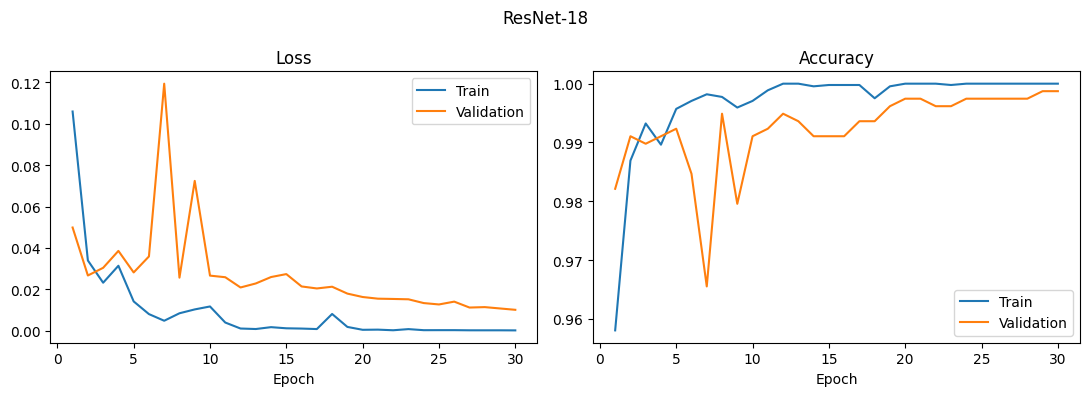


ResNet-18 classification report
              precision    recall  f1-score   support

      NORMAL       0.99      0.43      0.60       234
   PNEUMONIA       0.74      1.00      0.85       390

    accuracy                           0.78       624
   macro avg       0.87      0.71      0.72       624
weighted avg       0.84      0.78      0.76       624

ROC-AUC: 0.9435  | Confusion matrix:
 [[100 134]
 [  1 389]]


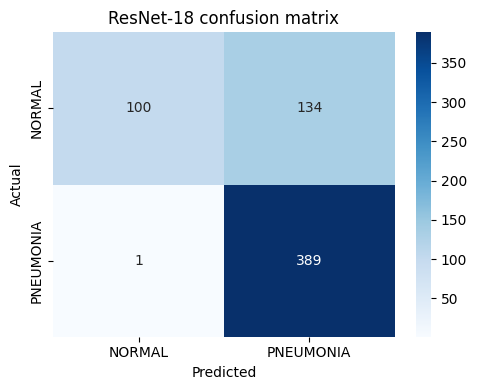

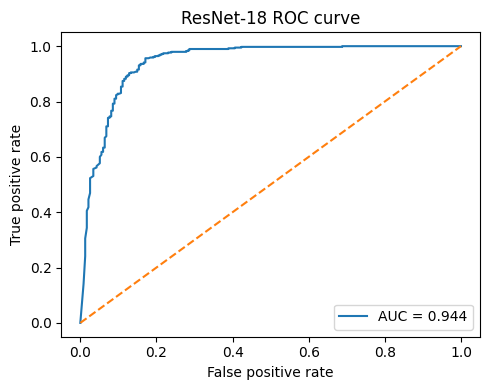


TRAINING GoogLeNet
Downloading: "https://download.pytorch.org/models/googlenet-1378be20.pth" to /root/.cache/torch/hub/checkpoints/googlenet-1378be20.pth


100%|██████████| 49.7M/49.7M [00:00<00:00, 158MB/s]


GoogLeNet epoch 1/30 | train loss 0.1340, acc 0.9583 | val loss 0.0508, acc 0.9808 | 80.1s
GoogLeNet epoch 2/30 | train loss 0.0484, acc 0.9822 | val loss 0.0383, acc 0.9885 | 81.0s
GoogLeNet epoch 3/30 | train loss 0.0295, acc 0.9903 | val loss 0.0435, acc 0.9834 | 80.3s
GoogLeNet epoch 4/30 | train loss 0.0203, acc 0.9950 | val loss 0.0381, acc 0.9872 | 80.4s
GoogLeNet epoch 5/30 | train loss 0.0151, acc 0.9953 | val loss 0.0313, acc 0.9923 | 79.9s
GoogLeNet epoch 6/30 | train loss 0.0129, acc 0.9948 | val loss 0.0293, acc 0.9923 | 79.5s
GoogLeNet epoch 7/30 | train loss 0.0067, acc 0.9986 | val loss 0.0549, acc 0.9860 | 80.3s
GoogLeNet epoch 8/30 | train loss 0.0119, acc 0.9964 | val loss 0.0333, acc 0.9923 | 79.6s
GoogLeNet epoch 9/30 | train loss 0.0040, acc 0.9986 | val loss 0.0253, acc 0.9936 | 80.7s
GoogLeNet epoch 10/30 | train loss 0.0041, acc 0.9993 | val loss 0.0336, acc 0.9898 | 79.2s
GoogLeNet epoch 11/30 | train loss 0.0015, acc 1.0000 | val loss 0.0322, acc 0.9911 | 80.

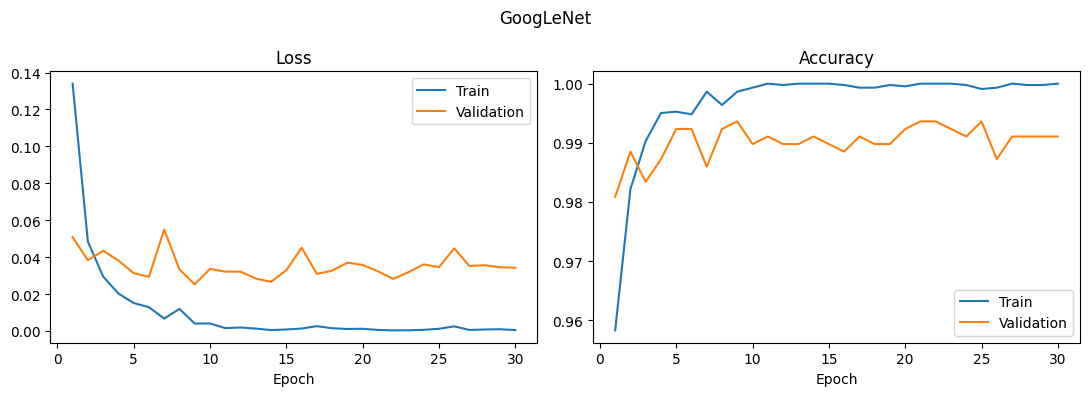


GoogLeNet classification report
              precision    recall  f1-score   support

      NORMAL       1.00      0.55      0.71       234
   PNEUMONIA       0.79      1.00      0.88       390

    accuracy                           0.83       624
   macro avg       0.89      0.77      0.79       624
weighted avg       0.87      0.83      0.82       624

ROC-AUC: 0.9312  | Confusion matrix:
 [[128 106]
 [  0 390]]


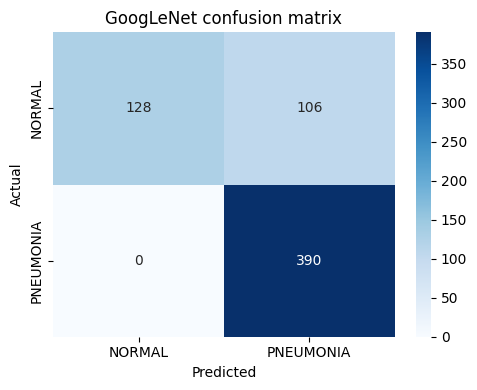

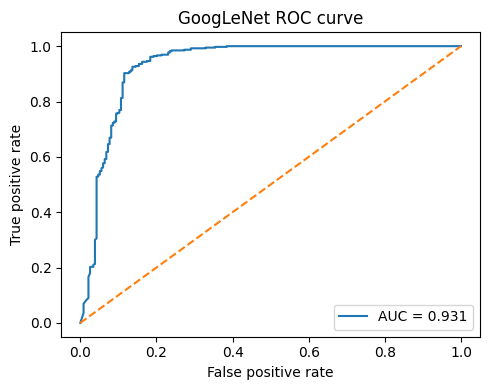


TRAINING DenseNet-121
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 166MB/s]


DenseNet121 epoch 1/30 | train loss 0.1072, acc 0.9632 | val loss 0.0442, acc 0.9834 | 89.3s
DenseNet121 epoch 2/30 | train loss 0.0404, acc 0.9853 | val loss 0.0370, acc 0.9860 | 88.4s
DenseNet121 epoch 3/30 | train loss 0.0209, acc 0.9930 | val loss 0.0259, acc 0.9885 | 88.3s
DenseNet121 epoch 4/30 | train loss 0.0183, acc 0.9939 | val loss 0.0805, acc 0.9745 | 89.2s
DenseNet121 epoch 5/30 | train loss 0.0123, acc 0.9957 | val loss 0.0558, acc 0.9783 | 88.7s
DenseNet121 epoch 6/30 | train loss 0.0144, acc 0.9950 | val loss 0.0298, acc 0.9898 | 89.0s
DenseNet121 epoch 7/30 | train loss 0.0086, acc 0.9975 | val loss 0.0141, acc 0.9987 | 88.6s
DenseNet121 epoch 8/30 | train loss 0.0037, acc 0.9995 | val loss 0.0113, acc 0.9962 | 89.7s
DenseNet121 epoch 9/30 | train loss 0.0028, acc 0.9995 | val loss 0.0301, acc 0.9923 | 88.8s
DenseNet121 epoch 10/30 | train loss 0.0060, acc 0.9984 | val loss 0.0580, acc 0.9808 | 89.6s
DenseNet121 epoch 11/30 | train loss 0.0036, acc 0.9993 | val loss 0.

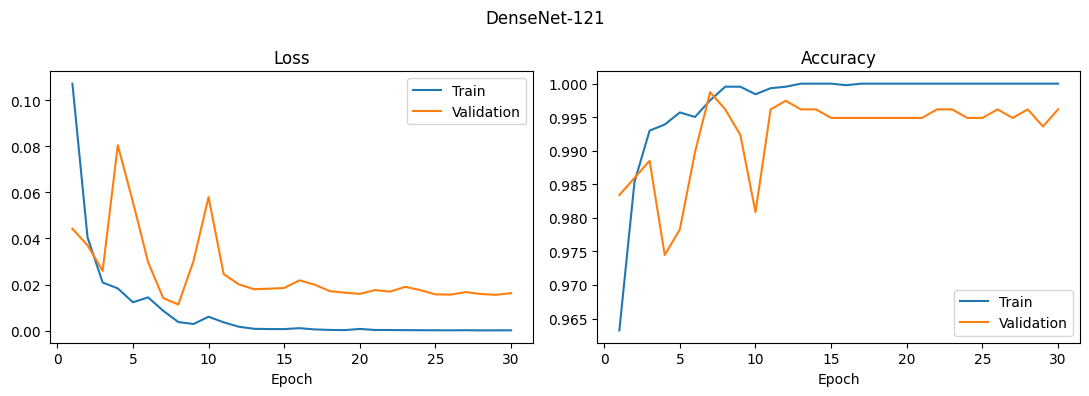


DenseNet-121 classification report
              precision    recall  f1-score   support

      NORMAL       0.99      0.33      0.50       234
   PNEUMONIA       0.71      1.00      0.83       390

    accuracy                           0.75       624
   macro avg       0.85      0.67      0.67       624
weighted avg       0.82      0.75      0.71       624

ROC-AUC: 0.8984  | Confusion matrix:
 [[ 78 156]
 [  1 389]]


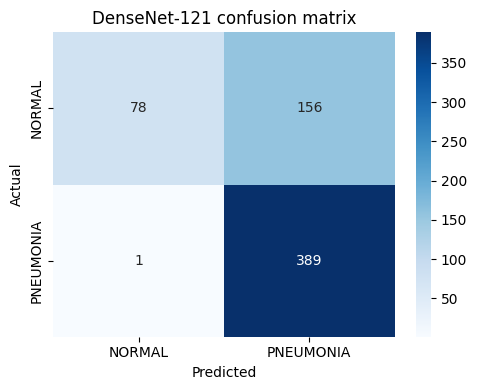

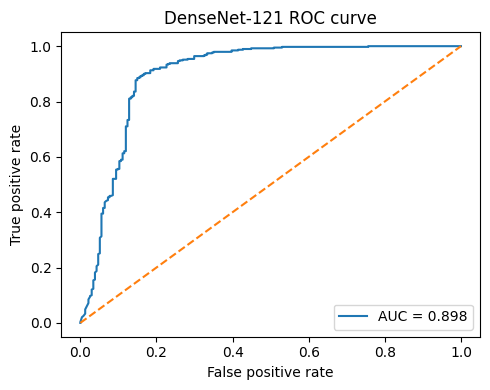

,Model,Accuracy,ROC_AUC,NORMAL_precision,NORMAL_recall,NORMAL_f1,PNEUMONIA_precision,PNEUMONIA_recall,PNEUMONIA_f1,Macro_F1
0,ResNet-18,0.7837,0.9435,0.9901,0.4274,0.5970,0.7438,0.9974,0.8521,0.7246
1,GoogLeNet,0.8301,0.9312,1.0000,0.5470,0.7072,0.7863,1.0000,0.8804,0.7938
2,DenseNet-121,0.7484,0.8984,0.9873,0.3333,0.4984,0.7138,0.9974,0.8321,0.6652


All three baseline models trained; checkpoints, histories, metrics and graphs saved.


In [5]:
baseline_models, baseline_histories, baseline_probs, baseline_results = {}, {}, {}, []
for model_name, display_name, prefix in [
    ("ResNet18","ResNet-18","resnet18"),
    ("GoogLeNet","GoogLeNet","googlenet"),
    ("DenseNet121","DenseNet-121","densenet121")
]:
    print("\n"+"="*70+"\nTRAINING "+display_name+"\n"+"="*70)
    model,hist=train_model(build_model(model_name,pretrained=True),model_name,BASELINE_EPOCHS,lr=1e-4)
    baseline_models[model_name]=model; baseline_histories[model_name]=hist
    plot_history(hist,display_name,prefix)
    probs,y_test_current=predict_model(model,test_loader)
    baseline_probs[model_name]=probs
    baseline_results.append(evaluate_probs(y_test_current,probs,display_name,prefix))

baseline_results_df=pd.DataFrame(baseline_results)
display(baseline_results_df.round(4))
baseline_results_df.to_csv(OUT_DIR/"baseline_model_results.csv",index=False)
print("All three baseline models trained; checkpoints, histories, metrics and graphs saved.")

## CELL 6 — Calculate the equal-probability ensemble and generate its classification report, confusion matrix and ROC curve.


Equal-probability ensemble classification report
              precision    recall  f1-score   support

      NORMAL       0.99      0.43      0.60       234
   PNEUMONIA       0.74      1.00      0.85       390

    accuracy                           0.78       624
   macro avg       0.87      0.71      0.72       624
weighted avg       0.84      0.78      0.76       624

ROC-AUC: 0.9331  | Confusion matrix:
 [[100 134]
 [  1 389]]


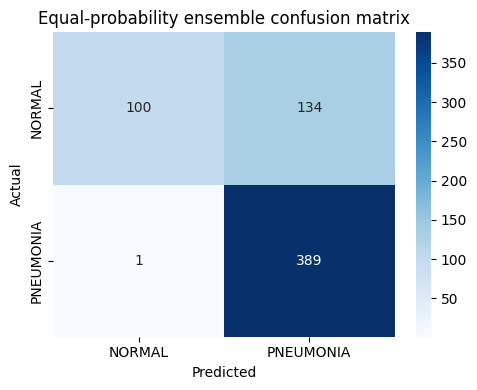

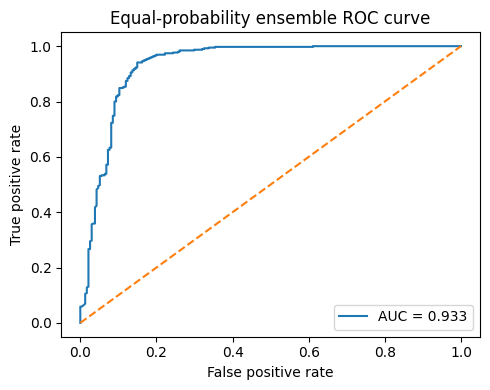

,Model,Accuracy,ROC_AUC,NORMAL_precision,NORMAL_recall,NORMAL_f1,PNEUMONIA_precision,PNEUMONIA_recall,PNEUMONIA_f1,Macro_F1
0,Equal-probability ensemble,0.7837,0.9331,0.9901,0.4274,0.597,0.7438,0.9974,0.8521,0.7246


Equal-probability ensemble evaluation complete.


In [6]:
ensemble_probs=np.mean([baseline_probs["ResNet18"],baseline_probs["GoogLeNet"],baseline_probs["DenseNet121"]],axis=0)
ensemble_result=evaluate_probs(y_test_current,ensemble_probs,"Equal-probability ensemble","ensemble")
ensemble_results_df=pd.DataFrame([ensemble_result])
display(ensemble_results_df.round(4))
ensemble_results_df.to_csv(OUT_DIR/"ensemble_results.csv",index=False)
print("Equal-probability ensemble evaluation complete.")

## CELL 7 — Define CBAM channel/spatial attention, insert it into DenseNet-121, fine-tune it, and generate learning curves plus test evaluation graphs.

CBAM-DenseNet121 trainable parameters: 7087076
CBAM epoch 1/15 | train loss 0.1102, acc 0.9989 | val loss 0.0616, acc 0.9974 | 95.2s
CBAM epoch 2/15 | train loss 0.0403, acc 0.9984 | val loss 0.0318, acc 0.9974 | 90.7s
CBAM epoch 3/15 | train loss 0.0203, acc 0.9984 | val loss 0.0216, acc 0.9962 | 90.8s
CBAM epoch 4/15 | train loss 0.0108, acc 0.9991 | val loss 0.0157, acc 0.9987 | 92.0s
CBAM epoch 5/15 | train loss 0.0089, acc 0.9989 | val loss 0.0165, acc 0.9936 | 92.2s
CBAM epoch 6/15 | train loss 0.0052, acc 0.9998 | val loss 0.0140, acc 0.9974 | 89.7s
CBAM epoch 7/15 | train loss 0.0043, acc 0.9998 | val loss 0.0113, acc 0.9962 | 91.3s
CBAM epoch 8/15 | train loss 0.0042, acc 0.9998 | val loss 0.0116, acc 0.9974 | 91.3s
CBAM epoch 9/15 | train loss 0.0038, acc 0.9998 | val loss 0.0108, acc 0.9974 | 91.0s
CBAM epoch 10/15 | train loss 0.0029, acc 0.9998 | val loss 0.0130, acc 0.9949 | 89.5s
CBAM epoch 11/15 | train loss 0.0024, acc 0.9998 | val loss 0.0121, acc 0.9949 | 91.6s
CBAM 

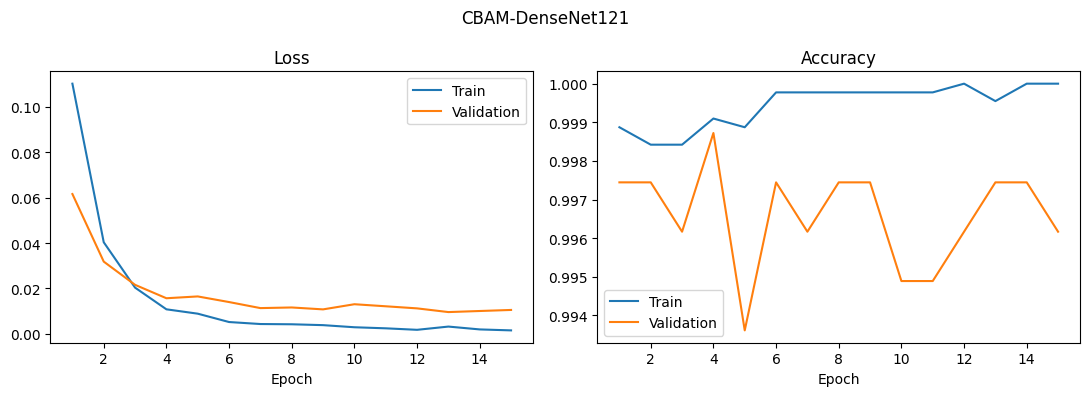


CBAM-DenseNet121 classification report
              precision    recall  f1-score   support

      NORMAL       0.99      0.47      0.64       234
   PNEUMONIA       0.76      1.00      0.86       390

    accuracy                           0.80       624
   macro avg       0.88      0.74      0.75       624
weighted avg       0.85      0.80      0.78       624

ROC-AUC: 0.9044  | Confusion matrix:
 [[111 123]
 [  1 389]]


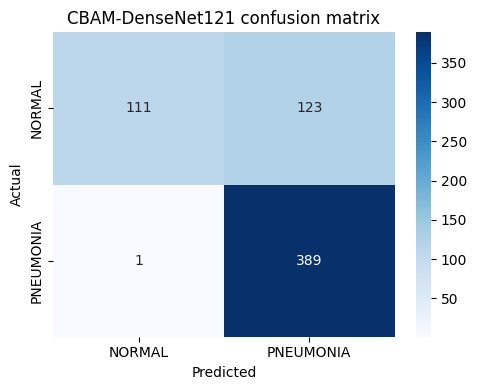

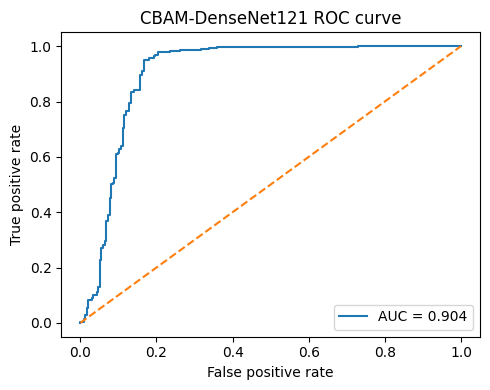

CBAM training and test evaluation complete.


In [9]:
class ChannelAttention(nn.Module):
    def __init__(self,channels,reduction=16):
        super().__init__()
        hidden=max(channels//reduction,1)
        self.mlp=nn.Sequential(nn.Conv2d(channels,hidden,1,bias=False),nn.ReLU(inplace=True),
                               nn.Conv2d(hidden,channels,1,bias=False))
        self.sigmoid=nn.Sigmoid()
    def forward(self,x):
        avg=torch.mean(x,dim=(2,3),keepdim=True)
        mx=torch.amax(x,dim=(2,3),keepdim=True)
        return x*self.sigmoid(self.mlp(avg)+self.mlp(mx))

class SpatialAttention(nn.Module):
    def __init__(self,kernel_size=7):
        super().__init__()
        self.conv=nn.Conv2d(2,1,kernel_size,padding=kernel_size//2,bias=False)
        self.sigmoid=nn.Sigmoid()
    def forward(self,x):
        avg=torch.mean(x,dim=1,keepdim=True)
        mx=torch.amax(x,dim=1,keepdim=True)
        att=self.sigmoid(self.conv(torch.cat([avg,mx],dim=1)))
        return x*att

class CBAM(nn.Module):
    def __init__(self,channels=1024):
        super().__init__()
        self.channel=ChannelAttention(channels)
        self.spatial=SpatialAttention(7)
    def forward(self,x):
        return self.spatial(self.channel(x))

class DenseNet121_CBAM(nn.Module):
    def __init__(self,pretrained=True,num_classes=2):
        super().__init__()
        weights=models.DenseNet121_Weights.DEFAULT if pretrained else None
        base=models.densenet121(weights=weights)
        self.features=base.features
        self.cbam=CBAM(1024)
        self.pool=nn.AdaptiveAvgPool2d((1,1))
        self.classifier=nn.Linear(1024,num_classes)
    def forward(self, x):
        x = self.features(x)
        x = torch.relu(x)
        x = self.cbam(x)
        x = self.pool(x).flatten(1)
        return self.classifier(x)

cbam_model=DenseNet121_CBAM(pretrained=True)
# Start from the trained DenseNet-121 backbone and classifier for a fair fine-tuning comparison.
cbam_model.features.load_state_dict(baseline_models["DenseNet121"].features.state_dict())
cbam_model.classifier.load_state_dict(baseline_models["DenseNet121"].classifier.state_dict())
cbam_model=cbam_model.to(DEVICE)
print("CBAM-DenseNet121 trainable parameters:",sum(p.numel() for p in cbam_model.parameters() if p.requires_grad))

criterion=nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(cbam_model.parameters(),lr=1e-5)
scheduler=torch.optim.lr_scheduler.StepLR(optimizer,step_size=5,gamma=0.5)
best_val=-1; cbam_history=[]; cbam_path=MODEL_DIR/"CBAM_DenseNet121_best.pth"
for epoch in range(1,CBAM_EPOCHS+1):
    t=time.time()
    tr_loss,tr_acc=run_epoch(cbam_model,train_loader,criterion,optimizer)
    va_loss,va_acc=run_epoch(cbam_model,val_loader,criterion)
    scheduler.step()
    cbam_history.append({"epoch":epoch,"train_loss":tr_loss,"train_accuracy":tr_acc,
                         "val_loss":va_loss,"val_accuracy":va_acc,"learning_rate":optimizer.param_groups[0]["lr"]})
    if va_acc>best_val:
        best_val=va_acc
        torch.save({"model_state_dict":cbam_model.state_dict(),"best_val_accuracy":best_val,
                    "class_to_idx":full_train.class_to_idx,"seed":SEED},cbam_path)
    print(f"CBAM epoch {epoch}/{CBAM_EPOCHS} | train loss {tr_loss:.4f}, acc {tr_acc:.4f} "
          f"| val loss {va_loss:.4f}, acc {va_acc:.4f} | {time.time()-t:.1f}s")
cbam_history=pd.DataFrame(cbam_history)
cbam_history.to_csv(OUT_DIR/"CBAM_DenseNet121_history.csv",index=False)
cbam_ckpt=torch.load(cbam_path,map_location=DEVICE)
cbam_model.load_state_dict(cbam_ckpt["model_state_dict"])
plot_history(cbam_history,"CBAM-DenseNet121","cbam_densenet121")
cbam_probs,y_test_current=predict_model(cbam_model,test_loader)
cbam_result=evaluate_probs(y_test_current,cbam_probs,"CBAM-DenseNet121","cbam_densenet121")
print("CBAM training and test evaluation complete.")

## CELL 8 — Compare all models, plot metric comparisons, run paired McNemar exact testing, and benchmark DenseNet-121 against CBAM-DenseNet121.

,Model,Accuracy,ROC_AUC,NORMAL_precision,NORMAL_recall,NORMAL_f1,PNEUMONIA_precision,PNEUMONIA_recall,PNEUMONIA_f1,Macro_F1
0,ResNet-18,0.7837,0.9435,0.9901,0.4274,0.5970,0.7438,0.9974,0.8521,0.7246
1,GoogLeNet,0.8301,0.9312,1.0000,0.5470,0.7072,0.7863,1.0000,0.8804,0.7938
2,DenseNet-121,0.7484,0.8984,0.9873,0.3333,0.4984,0.7138,0.9974,0.8321,0.6652
3,Equal-probability ensemble,0.7837,0.9331,0.9901,0.4274,0.5970,0.7438,0.9974,0.8521,0.7246
4,CBAM-DenseNet121,0.8013,0.9044,0.9911,0.4744,0.6416,0.7598,0.9974,0.8625,0.7521


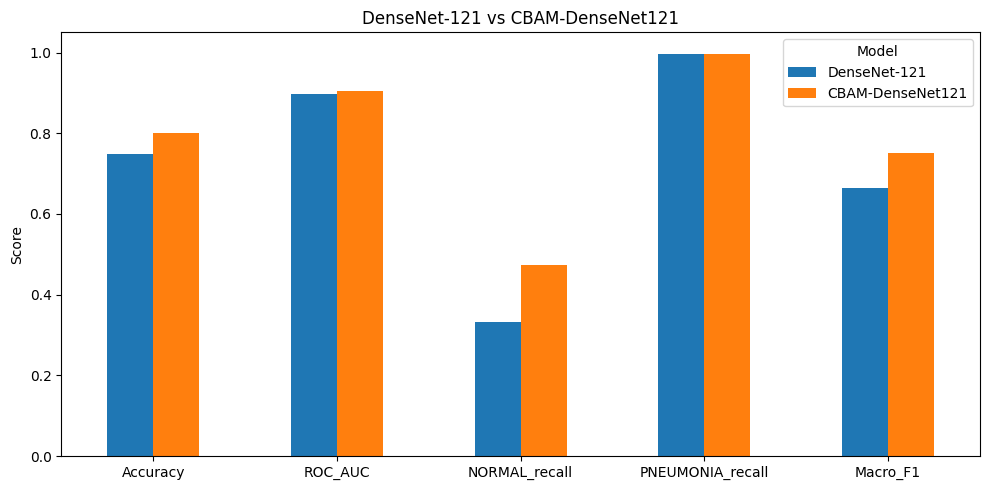

Baseline correct / CBAM incorrect: 3
Baseline incorrect / CBAM correct: 36
McNemar exact two-sided p-value: 3.608874976634979e-08


,Model,latency_ms_per_image,throughput_images_per_sec,peak_allocated_GPU_MB
0,DenseNet-121,3.136,318.921,8765.591
1,CBAM-DenseNet121,3.287,304.205,8765.591


Comparison, paired statistical test and inference benchmark saved.


In [10]:
all_results=pd.DataFrame(baseline_results+[ensemble_result,cbam_result])
display(all_results.round(4))
all_results.to_csv(OUT_DIR/"all_model_results.csv",index=False)

# Comparison graph: baseline DenseNet versus CBAM DenseNet
compare_df=pd.DataFrame([baseline_results[2],cbam_result]).set_index("Model")
metric_cols=["Accuracy","ROC_AUC","NORMAL_recall","PNEUMONIA_recall","Macro_F1"]
ax=compare_df[metric_cols].T.plot(kind="bar",figsize=(10,5))
ax.set_title("DenseNet-121 vs CBAM-DenseNet121"); ax.set_ylabel("Score")
ax.set_ylim(0,1.05); plt.xticks(rotation=0); plt.tight_layout()
plt.savefig(FIG_DIR/"model_comparison_densenet_cbam.png",dpi=200); plt.show()

# Paired McNemar exact test on the same test images
base_pred=baseline_probs["DenseNet121"].argmax(axis=1)
cbam_pred=cbam_probs.argmax(axis=1)
base_correct=base_pred==y_test_current; cbam_correct=cbam_pred==y_test_current
n01=int(np.sum(base_correct & ~cbam_correct))
n10=int(np.sum(~base_correct & cbam_correct))
discordant=n01+n10
p_value=binomtest(min(n01,n10),n=discordant,p=0.5,alternative="two-sided").pvalue if discordant else 1.0
print("Baseline correct / CBAM incorrect:",n01)
print("Baseline incorrect / CBAM correct:",n10)
print("McNemar exact two-sided p-value:",p_value)
pd.DataFrame([{"baseline_correct_cbam_wrong":n01,"baseline_wrong_cbam_correct":n10,
               "mcnemar_exact_p":p_value}]).to_csv(OUT_DIR/"mcnemar_exact_test.csv",index=False)

# Inference benchmark (batch of up to 32; 10 warmups, 50 repetitions)
def benchmark(model,warmup=10,repeats=50):
    model.eval()
    x,_=next(iter(test_loader)); x=x[:BATCH_SIZE].to(DEVICE)
    if DEVICE.type=="cuda":
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    with torch.no_grad():
        for _ in range(warmup): _=model(x)
        if DEVICE.type=="cuda": torch.cuda.synchronize()
        start=time.perf_counter()
        for _ in range(repeats): _=model(x)
        if DEVICE.type=="cuda": torch.cuda.synchronize()
        elapsed=time.perf_counter()-start
    ms=elapsed*1000/(repeats*len(x))
    mem=torch.cuda.max_memory_allocated()/(1024**2) if DEVICE.type=="cuda" else np.nan
    return {"latency_ms_per_image":ms,"throughput_images_per_sec":1000/ms,"peak_allocated_GPU_MB":mem}

bench=pd.DataFrame([
    {"Model":"DenseNet-121",**benchmark(baseline_models["DenseNet121"])},
    {"Model":"CBAM-DenseNet121",**benchmark(cbam_model)}
])
display(bench.round(3))
bench.to_csv(OUT_DIR/"inference_benchmark.csv",index=False)
print("Comparison, paired statistical test and inference benchmark saved.")

## CELL 9 — Export every test prediction, save experiment configuration, collect report figures/checkpoints/CSVs, and download one ZIP archive.

In [11]:
# Save all probability scores and class predictions for later audit/report preparation.
predictions=pd.DataFrame({"true_label":y_test_current})
for key,probs in baseline_probs.items():
    safe=key.lower()
    predictions[f"{safe}_p_normal"]=probs[:,0]
    predictions[f"{safe}_p_pneumonia"]=probs[:,1]
    predictions[f"{safe}_prediction"]=probs.argmax(axis=1)
predictions["ensemble_p_normal"]=ensemble_probs[:,0]
predictions["ensemble_p_pneumonia"]=ensemble_probs[:,1]
predictions["ensemble_prediction"]=ensemble_probs.argmax(axis=1)
predictions["cbam_p_normal"]=cbam_probs[:,0]
predictions["cbam_p_pneumonia"]=cbam_probs[:,1]
predictions["cbam_prediction"]=cbam_probs.argmax(axis=1)
predictions.to_csv(OUT_DIR/"all_test_predictions.csv",index=False)

config={"seed":SEED,"image_size":IMG_SIZE,"batch_size":BATCH_SIZE,
        "baseline_epochs":BASELINE_EPOCHS,"cbam_epochs":CBAM_EPOCHS,
        "device":str(DEVICE),"pytorch":torch.__version__,
        "torchvision":__import__("torchvision").__version__,
        "dataset":"paultimothymooney/chest-xray-pneumonia",
        "validation_protocol":"stratified 15% split from original training folder"}
with open(OUT_DIR/"experiment_config.json","w") as f: json.dump(config,f,indent=2)

print("FINAL MODEL RESULTS")
display(all_results.round(4))
print("\nREPORT FIGURES")
for p in sorted(FIG_DIR.glob("*.png")): print(p.name)
print("\nCSV OUTPUTS")
for p in sorted(OUT_DIR.glob("*.csv")): print(p.name)

archive="/content/Pneumonia_Project_Complete_Results.zip"
if os.path.exists(archive): os.remove(archive)
shutil.make_archive(archive[:-4],"zip",ROOT)
print("\nCreated:",archive)
from google.colab import files
files.download(archive)

FINAL MODEL RESULTS


,Model,Accuracy,ROC_AUC,NORMAL_precision,NORMAL_recall,NORMAL_f1,PNEUMONIA_precision,PNEUMONIA_recall,PNEUMONIA_f1,Macro_F1
0,ResNet-18,0.7837,0.9435,0.9901,0.4274,0.5970,0.7438,0.9974,0.8521,0.7246
1,GoogLeNet,0.8301,0.9312,1.0000,0.5470,0.7072,0.7863,1.0000,0.8804,0.7938
2,DenseNet-121,0.7484,0.8984,0.9873,0.3333,0.4984,0.7138,0.9974,0.8321,0.6652
3,Equal-probability ensemble,0.7837,0.9331,0.9901,0.4274,0.5970,0.7438,0.9974,0.8521,0.7246
4,CBAM-DenseNet121,0.8013,0.9044,0.9911,0.4744,0.6416,0.7598,0.9974,0.8625,0.7521



REPORT FIGURES
01_dataset_distribution.png
02_sample_xrays.png
cbam_densenet121_confusion_matrix.png
cbam_densenet121_learning_curves.png
cbam_densenet121_roc_curve.png
densenet121_confusion_matrix.png
densenet121_learning_curves.png
densenet121_roc_curve.png
ensemble_confusion_matrix.png
ensemble_roc_curve.png
googlenet_confusion_matrix.png
googlenet_learning_curves.png
googlenet_roc_curve.png
model_comparison_densenet_cbam.png
resnet18_confusion_matrix.png
resnet18_learning_curves.png
resnet18_roc_curve.png

CSV OUTPUTS
CBAM_DenseNet121_history.csv
DenseNet121_history.csv
GoogLeNet_history.csv
ResNet18_history.csv
all_model_results.csv
all_test_predictions.csv
baseline_model_results.csv
cbam_densenet121_classification_report.csv
cbam_densenet121_confusion_matrix.csv
densenet121_classification_report.csv
densenet121_confusion_matrix.csv
ensemble_classification_report.csv
ensemble_confusion_matrix.csv
ensemble_results.csv
googlenet_classification_report.csv
googlenet_confusion_matrix.

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
import os
from google.colab import files

zip_path = "/content/Pneumonia_Project_Complete_Results.zip"

if os.path.exists(zip_path):
    print("ZIP file found!")
    print("File size:", round(os.path.getsize(zip_path) / (1024**2), 2), "MB")
    files.download(zip_path)
else:
    print("ZIP file not found in the current runtime.")

ZIP file not found in the current runtime.


## Report screenshot checklist

The experiment cells above automatically save the figures in `outputs/figures/` and print the supporting metrics in their own output areas.

| Required report evidence | Generated by |
|---|---|
| GPU/software environment | Cell 1 |
| Dataset folders and class counts | Cells 2–3 |
| Dataset class-distribution chart | Cell 3 |
| Representative X-ray images | Cell 3 |
| Baseline learning curves, classification reports, confusion matrices and ROC curves | Cell 5 |
| Ensemble classification report, confusion matrix and ROC curve | Cell 6 |
| CBAM architecture, training logs, learning curves, classification report, confusion matrix and ROC curve | Cell 7 |
| DenseNet vs CBAM metric comparison | Cell 8 |
| McNemar paired test and inference benchmark | Cell 8 |
| All result files and ZIP archive | Cell 9 |

**Important for the final report:** use the actual metrics generated by this run. Do not copy old experiment scores as if they came from this run. The test set is reused during this academic experiment, so do not describe it as a completely untouched external validation set. Save the downloaded ZIP and upload it in this chat when the run finishes; it contains the figures, CSVs, prediction scores, configuration and model checkpoints needed to assemble the report.